# 09. KNN Regressor

**Project** · Food Delivery Time Prediction  
**Problem type** · Regression

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

KNN regression estimates a continuous outcome by averaging outcomes from similar training examples. For food delivery, it uses observed delivery durations from orders with comparable distance, conditions and preparation time.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Delivery time adds preparation, base travel time, a distance-by-traffic penalty and a nonlinear weather penalty. Rider experience reduces time with diminishing returns. Gaussian noise of 4.3 minutes is added and the target is floored at seven minutes.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `delivery_distance_km` | decimal | km | Road distance for the delivery |
| `traffic_level` | integer | ordinal 1 to 5 | Increasing traffic intensity |
| `preparation_time_min` | decimal | min | Estimated preparation duration |
| `weather_severity` | integer | ordinal 0 to 3 | Increasing severity of weather |
| `rider_experience_years` | decimal | years | Rider’s delivery experience |
| `delivery_time_min` | decimal | min | Observed continuous outcome |

**Independent variables (X)** · `delivery_distance_km`, `traffic_level`, `preparation_time_min`, `weather_severity`, `rider_experience_years`.

**Dependent variable (y)** · `delivery_time_min` is the continuous quantity to predict in min. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "09_food_delivery.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,delivery_distance_km,traffic_level,preparation_time_min,weather_severity,rider_experience_years,delivery_time_min
0,10.79,5,11.9,1,0.9,62.4
1,14.81,3,10.7,3,6.5,72.0
2,12.17,3,25.5,0,3.0,72.6
3,11.68,3,19.7,3,7.0,73.6
4,14.46,2,22.3,3,0.2,84.8
5,3.46,3,23.3,0,2.0,42.7
6,8.67,4,10.4,0,1.6,38.2
7,4.86,2,18.4,3,3.2,32.0
8,12.84,2,14.1,3,5.1,65.2
9,2.12,5,6.9,3,5.5,10.7


delivery_distance_km      float64
traffic_level               int64
preparation_time_min      float64
weather_severity            int64
rider_experience_years    float64
delivery_time_min         float64
dtype: object

## 3. Mathematical Understanding

Find $K$ neighbours using Euclidean distance $d_i=\sqrt{\sum_j(x_j-z_{ij})^2}$ between the query $x$ and neighbour $z_i$ over transformed features $j$. Predict $\hat y=\sum_i w_i y_i/\sum_i w_i$, where $y_i$ is neighbour $i$’s outcome and $w_i$ its weight. Uniform weighting sets $w_i=1$. Distance weighting uses inverse distance for nonzero distances. When exact matches occur, scikit-learn gives those matches all the weight.

For outcomes $22$, $30$ and $40$ min, the unweighted mean is $30.67$ min. At distances 1, 2 and 4 the weights are 1, 0.5 and 0.25, yielding $(22+15+10)/1.75\approx26.86$ min.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/neighbors.html)

## 4. Working Principle

Keep a reference collection of completed orders. Fit a training-only scaler so kilometres, minutes and ordinal levels do not compete solely on their numeric magnitudes. Compute distances to a new order, select K rows and average their tracked durations.

| Example | Distance | Duration | Weight |
| --- | --- | --- | --- |
| Neighbour 1 | 1 | 22 min | 1.00 |
| Neighbour 2 | 2 | 30 min | 0.50 |
| Neighbour 3 | 4 | 40 min | 0.25 |

**Workflow diagram**

`Raw input` → `Standardized numeric values and any category indicators` → `Averages continuous outcomes in a neighbourhood` → `Estimate in min`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows the range and shape of the outcome. Feature plots show variation. Pearson correlation measures linear association. Watch for nonlinear trends even if a linear association is present. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "delivery_time_min"
FEATURES = ["delivery_distance_km","traffic_level","preparation_time_min","weather_severity","rider_experience_years"]
NUMERIC = ["delivery_distance_km","traffic_level","preparation_time_min","weather_severity","rider_experience_years"]
CATEGORICAL = []
SEED = 42

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   delivery_distance_km    1500 non-null   float64
 1   traffic_level           1500 non-null   int64  
 2   preparation_time_min    1500 non-null   float64
 3   weather_severity        1500 non-null   int64  
 4   rider_experience_years  1470 non-null   float64
 5   delivery_time_min       1500 non-null   float64
dtypes: float64(4), int64(2)
memory usage: 70.4 KB


,delivery_distance_km,traffic_level,preparation_time_min,weather_severity,rider_experience_years,delivery_time_min
0,10.79,5,11.9,1,0.9,62.4
1,14.81,3,10.7,3,6.5,72.0
2,12.17,3,25.5,0,3.0,72.6
3,11.68,3,19.7,3,7.0,73.6
4,14.46,2,22.3,3,0.2,84.8


,delivery_distance_km,traffic_level,preparation_time_min,weather_severity,rider_experience_years,delivery_time_min
1495,8.06,1,13.1,3,6.4,35.2
1496,8.86,2,26.6,2,2.5,53.1
1497,1.63,4,18.1,2,5.9,20.0
1498,12.82,4,11.6,1,5.5,63.7
1499,7.87,3,18.4,2,0.2,46.7


,count,mean,std,min,25%,50%,75%,max
delivery_distance_km,1500.0,7.931700,4.208132,0.51,4.3375,7.96,11.5625,15.0
traffic_level,1500.0,2.975333,1.408089,1.00,2.0000,3.00,4.0000,5.0
preparation_time_min,1500.0,18.286533,7.833937,5.10,11.6000,18.00,25.4000,32.0
weather_severity,1500.0,1.483333,1.137212,0.00,0.0000,1.00,3.0000,3.0
rider_experience_years,1470.0,3.442789,1.970780,0.00,1.8000,3.30,5.1750,7.0
delivery_time_min,1500.0,47.425333,19.030896,7.00,33.5750,45.90,60.6250,106.7


,Missing,Missing %
delivery_distance_km,0,0.0
traffic_level,0,0.0
preparation_time_min,0,0.0
weather_severity,0,0.0
rider_experience_years,30,2.0
delivery_time_min,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

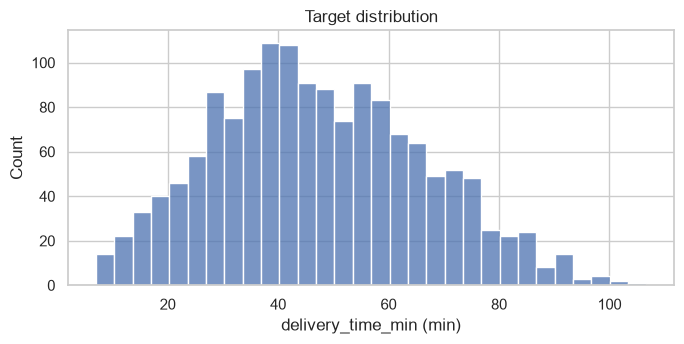

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.histplot(data=df, x=TARGET, bins=30, ax=ax)
ax.set_xlabel("delivery_time_min (min)")
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

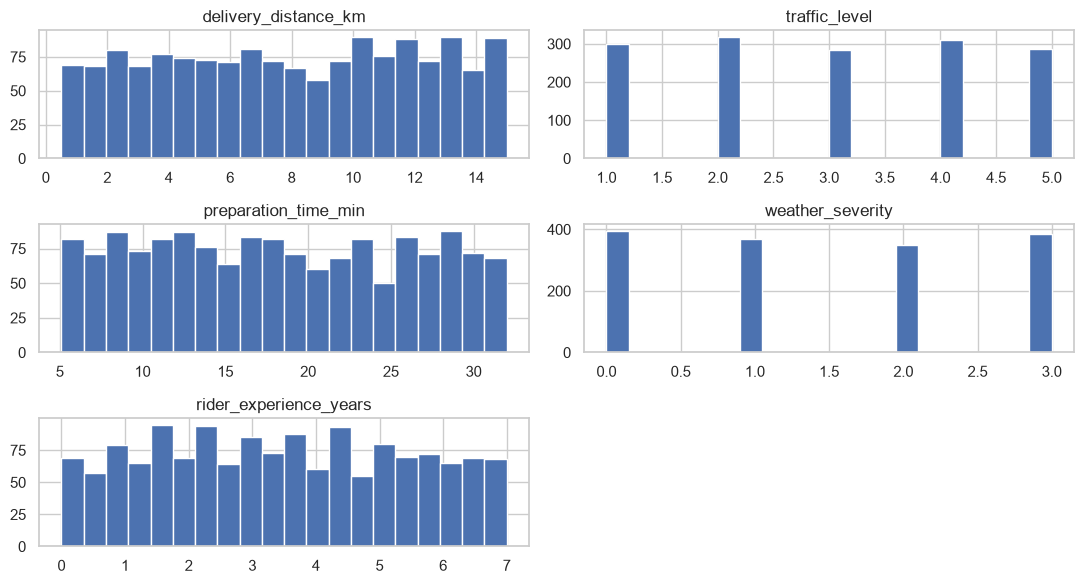

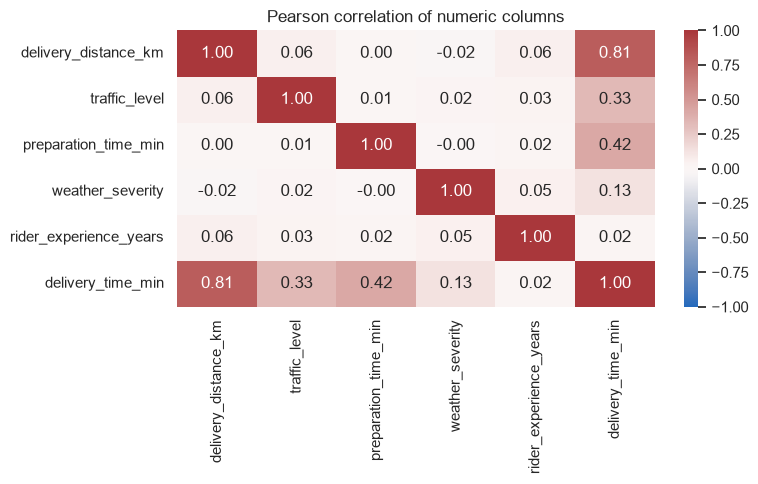

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC + [TARGET]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. A seeded random split suits these independently generated rows. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
y = df[TARGET]

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`n_neighbors` controls how local the average is. `weights='distance'` emphasizes nearby orders. `p=1` or `p=2` chooses Manhattan or Euclidean distance under Minkowski. Treating ordinal levels as numbers assumes equal increments within each scale.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.neighbors import KNeighborsRegressor

estimator = KNeighborsRegressor(n_neighbors=11, weights="distance", metric="minkowski", p=2)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['delivery_distance_km','traffic_level','preparation_time_min', 'weather_severity','rider_experience_years']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not pr

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print(f"Example prediction: {predictions[0]:,.2f} min")

,delivery_distance_km,traffic_level,preparation_time_min,weather_severity,rider_experience_years
1116,11.73,4,31.0,0,2.1


Example prediction: 75.91 min


## 8. Model Evaluation

Let $y_i$ be the actual test value for row $i$, $\hat y_i$ its prediction, $e_i=y_i-\hat y_i$ its residual, $n$ the number of test rows and $\bar y$ the test target mean.

| Metric | Formula | Interpretation |
| --- | --- | --- |
| Mean absolute error | $\mathrm{MAE}=n^{-1}\sum_i\lvert e_i\rvert$ | Mean absolute miss in the target unit. Lower is better. |
| Mean squared error | $\mathrm{MSE}=n^{-1}\sum_i e_i^2$ | Mean squared miss in squared units. It puts more weight on large errors. Lower is better. |
| Root mean squared error | $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ | Error on the target scale that emphasizes large misses. Lower is better. |
| Coefficient of determination | $R^2=1-\sum_i e_i^2/\sum_i(y_i-\bar y)^2$ | Higher is better. One is a perfect fit, zero matches the squared error of the test mean, and negative means more error than that reference. |

The baseline predicts the **training** target mean, so its test R² may be slightly negative. Compare MAE and RMSE to it in the table below.

**Target unit** · min.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

initial_metrics = {
    "MAE": mean_absolute_error(y_test, predictions),
    "MSE": mean_squared_error(y_test, predictions),
    "RMSE": root_mean_squared_error(y_test, predictions),
    "R²": r2_score(y_test, predictions),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

MAE      4.428
MSE     30.668
RMSE     5.538
R²       0.920
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline predicts the mean training target for every row.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_metrics = {
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "MSE": mean_squared_error(y_test, baseline_predictions),
    "RMSE": root_mean_squared_error(y_test, baseline_predictions),
    "R²": r2_score(y_test, baseline_predictions),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,MAE,MSE,RMSE,R²
Baseline,16.225,390.576,19.763,-0.017
Model,4.428,30.668,5.538,0.920


## 9. Visualizations

Compare estimated and measured outcomes against the 45-degree line. A point above that line is an overestimate. In the residual panel, points above zero are underestimates. A systematic curve suggests missing structure, and widening scatter suggests changing error spread.

The neighbour chart places the closest training orders on the horizontal distance scale. Nearby points contribute more to the predicted duration. Differences between neighbours help explain why two similar queries can have meaningful prediction error.

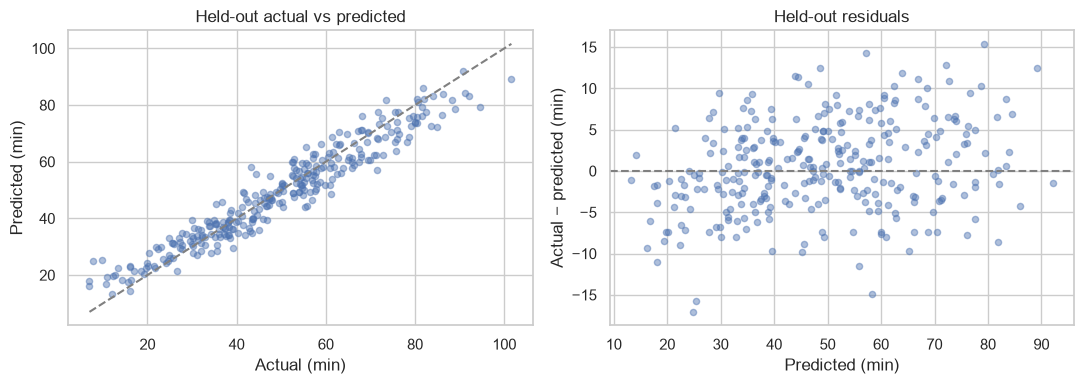

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].scatter(y_test, predictions, s=20, alpha=0.45)
axes[0].plot(limits, limits, color="grey", linestyle="--")
axes[0].set(xlabel="Actual (min)", ylabel="Predicted (min)", title="Held-out actual vs predicted")
axes[1].scatter(predictions, y_test - predictions, s=20, alpha=0.45)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set(xlabel="Predicted (min)", ylabel="Actual − predicted (min)", title="Held-out residuals")
fig.tight_layout()
plt.show()

### A closer look at this model

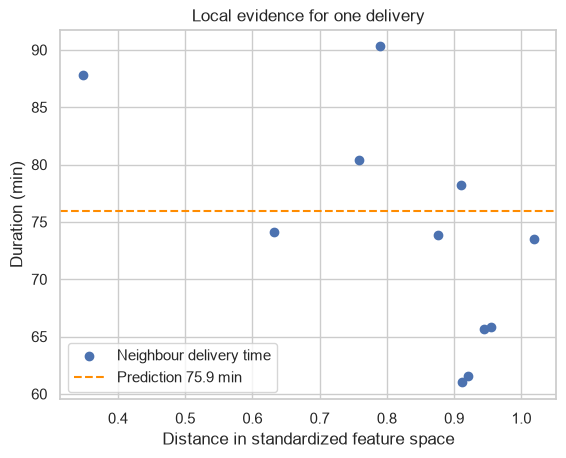

In [15]:
query = model.named_steps["preprocess"].transform(X_test.iloc[[0]])
distances, indices = model.named_steps["model"].kneighbors(query)
neighbor_minutes = y_train.iloc[indices[0]].to_numpy()
fig, ax = plt.subplots()
ax.scatter(distances[0], neighbor_minutes, label="Neighbour delivery time")
ax.axhline(predictions[0], color="darkorange", linestyle="--", label=f"Prediction {predictions[0]:.1f} min")
ax.set(xlabel="Distance in standardized feature space", ylabel="Duration (min)", title="Local evidence for one delivery")
ax.legend()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by lowest RMSE. The scorer negates RMSE so that the best score ranks first. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`n_neighbors` controls how local the average is. `weights='distance'` emphasizes nearby orders. `p=1` or `p=2` chooses Manhattan or Euclidean distance under Minkowski. Treating ordinal levels as numbers assumes equal increments within each scale.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {"model__n_neighbors": [5, 11, 23], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}
validation = KFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="neg_root_mean_squared_error", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [17]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean fold RMSE"] = -results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean fold RMSE", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'distance'}


,rank_test_score,Mean fold RMSE,std_test_score,params
7,1,5.777,0.091,"{'model__n_neighbors': 11, 'model__p': 2, 'mod..."
5,2,5.907,0.160,"{'model__n_neighbors': 11, 'model__p': 1, 'mod..."
6,3,5.931,0.112,"{'model__n_neighbors': 11, 'model__p': 2, 'mod..."
3,4,5.950,0.087,"{'model__n_neighbors': 5, 'model__p': 2, 'mode..."
11,5,6.014,0.196,"{'model__n_neighbors': 23, 'model__p': 2, 'mod..."


### Compare the models on the test set

In [18]:
tuned_predictions = tuned_model.predict(X_test)

tuned_metrics = {
    "MAE": mean_absolute_error(y_test, tuned_predictions),
    "MSE": mean_squared_error(y_test, tuned_predictions),
    "RMSE": root_mean_squared_error(y_test, tuned_predictions),
    "R²": r2_score(y_test, tuned_predictions),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,MAE,MSE,RMSE,R²
Baseline,16.225,390.576,19.763,-0.017
First model,4.428,30.668,5.538,0.920
Tuned model,4.428,30.668,5.538,0.920


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. Read the estimates in min and compare the scenarios to see how the fitted model responds.

### Enter three new examples

In [19]:
examples = pd.DataFrame([
    [2, 1, 10, 0, 4.5],
    [7.5, 3, 18, 1, 2],
    [13.1, 5, 24, 3, 0.8],
], columns=FEATURES)
display(examples)

,delivery_distance_km,traffic_level,preparation_time_min,weather_severity,rider_experience_years
0,2.0,1,10,0,4.5
1,7.5,3,18,1,2.0
2,13.1,5,24,3,0.8


### Make predictions

In [20]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Short trip in clear conditions","Medium trip in moderate traffic","Long trip in severe conditions"]
example_output["Predicted delivery_time_min (min)"] = sample_predictions.round(2)
display(example_output)

,delivery_distance_km,traffic_level,preparation_time_min,weather_severity,rider_experience_years,Scenario,Predicted delivery_time_min (min)
0,2.0,1,10,0,4.5,Short trip in clear conditions,14.27
1,7.5,3,18,1,2.0,Medium trip in moderate traffic,45.98
2,13.1,5,24,3,0.8,Long trip in severe conditions,86.36


## 12. Limitations and Advantages

It is intuitive and can model interactions without writing a global formula. It needs a meaningful metric and enough orders in each neighbourhood. Small K can retain label noise and large K can blur traffic effects. Predictions interpolate observed times and become slow with very large reference sets. Use for compact, representative datasets. Prefer another model if sparse regions or extrapolation matter.

## 13. Interview Preparation

### A. 30-second explanation

> I predicted food delivery times by finding similar historical orders. The pipeline imputes and scales the inputs, then KNN forms a distance-weighted average of nearby durations. I tuned the neighbour count and distance settings on training folds and reported holdout errors in minutes.

### B. 90-second technical explanation

> I predicted food delivery times by finding similar historical orders. The pipeline imputes and scales the inputs, then KNN forms a distance-weighted average of nearby durations. I tuned the neighbour count and distance settings on training folds and reported holdout errors in minutes. My target was delivery time min, and the inputs were delivery distance km, traffic level, preparation time min, weather severity, rider experience years. Keep a reference collection of completed orders. Fit a training-only scaler so kilometres, minutes and ordinal levels do not compete solely on their numeric magnitudes. Compute distances to a new order, select K rows and average their tracked durations. I held out 20% of the rows and fitted preprocessing within each training fold. I measured MAE in min and RMSE to see how much larger errors mattered. I compared the model with a training-mean predictor and inspected residuals. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **How does KNN regression differ from classification?** It averages numeric targets instead of voting for a class.
2. **What is a distance-weighted estimate?** A weighted average that gives closer training rows greater influence.
3. **What if a query has exact training matches?** Only exact matches contribute when distance weighting is selected.
4. **Why keep the training rows?** They define the neighbourhood available at inference time.
5. **Why scale distance and preparation minutes?** Their original units would otherwise assign implicit feature weights.
6. **Can predictions be larger than every training time?** A nonnegative weighted average stays within the training target range.
7. **What does high K do near a local peak?** It tends to smooth the peak toward surrounding values.
8. **What is the cost of brute-force inference?** Each query can compare with every training row, with work also growing with feature count.
9. **Should traffic level always be numeric?** Only if treating nearby levels as comparably spaced is reasonable.
10. **What metric summarizes a typical absolute error in minutes?** MAE.

### D. Five scenario questions

1. **A storm is outside the training range. What do you expect?** A weighted average of known orders, with weak evidence for extreme delays.
2. **Nearest neighbours have wildly different delivery times. What would you inspect?** Check whether important route features are missing and examine neighbourhood distances.
3. **There is a real preparation duration recorded after pickup. Use it for a prediction at checkout?** Use an estimate available at checkout to avoid look-ahead.
4. **Delivery zones change. How would you validate?** Test on later orders or on held-out zones, matching the deployment question.
5. **The model runs too slowly at checkout. Which measurements help?** Measure neighbour-search latency at representative dataset sizes and compare alternatives.

### E. Three common mistakes

- Averaging distances instead of delivery durations. Distances determine weights.
- Using a post-order actual preparation time in an order-time model. Use a forecast.
- Assuming a small neighbour distance guarantees a correct estimate. Check local outcome spread.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [21]:
from IPython.display import Markdown

summary = (
    "I built a supervised regression project for food delivery time prediction using KNN Regressor. I generated 1,500 synthetic observations and used delivery distance km, traffic level, preparation time min, weather severity, rider experience years to predict delivery time min. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model achieved MAE {tuned_metrics['MAE']:,.2f} min, "
    f"compared with {baseline_metrics['MAE']:,.2f} min for the training-mean baseline. "
    f"Its RMSE was {tuned_metrics['RMSE']:,.2f} min. "
    "I compared standardized distances with neighbour durations to explain one estimate. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised regression project for food delivery time prediction using KNN Regressor. I generated 1,500 synthetic observations and used delivery distance km, traffic level, preparation time min, weather severity, rider experience years to predict delivery time min. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model achieved MAE 4.43 min, compared with 16.22 min for the training-mean baseline. Its RMSE was 5.54 min. I compared standardized distances with neighbour durations to explain one estimate. These results apply to the synthetic data and should be validated on representative observations before practical use.